In [1]:
# ruff: noqa: F405
from functools import partial
from pathlib import Path
from pickle import dump, load

import anndata as ad
import numpy as np
import scanpy as sc
from plotnine import *  # noqa: F403
from shared import pl_k_sP, psc_ds, run_nmf, run_proc_per_ds, viz_defs

import spatialpeeler as sP
from spatialpeeler.diag import comp_sparsity, sweep_uns

viz_defs()
RAND_SEED = 28
# define helper function for plotting
pl_help = partial(pl_k_sP, cond_lab="group", sample_lab="sample_id", ctl_val="CTL")

In [2]:
# load dataset + run NMF
if (pth := Path("../.cache/psc.pkl")).exists():
    with open(pth, "rb") as f:
        psc = load(f)
else:
    adatas = psc_ds(
        Path("../data/psc-visium"),
    )
    for k in adatas:
        adatas[k] = adatas[k][adatas[k].obs["in_tissue"], :]

    run_proc_per_ds(adatas)

    psc = ad.concat(adatas, label="sample_id", index_unique="_")
    sc.pp.filter_genes(psc, min_cells=psc.n_obs // 500)

    run_nmf(psc, 30, RAND_SEED)

    pth.parent.mkdir(exist_ok=True)
    with open(pth, "wb") as f:
        dump(psc, f)
print(psc)

AnnData object with n_obs × n_vars = 21553 × 16465
    obs: 'in_tissue', 'percent.mt', 'cell_type', 'group', 'sample_id'
    var: 'n_cells'
    obsm: 'spatial', 'X_nmf'
    varm: 'X_nmf'
    layers: 'counts'


with our processed data, we proceed with the factor-wise regression step of spatialPeeler

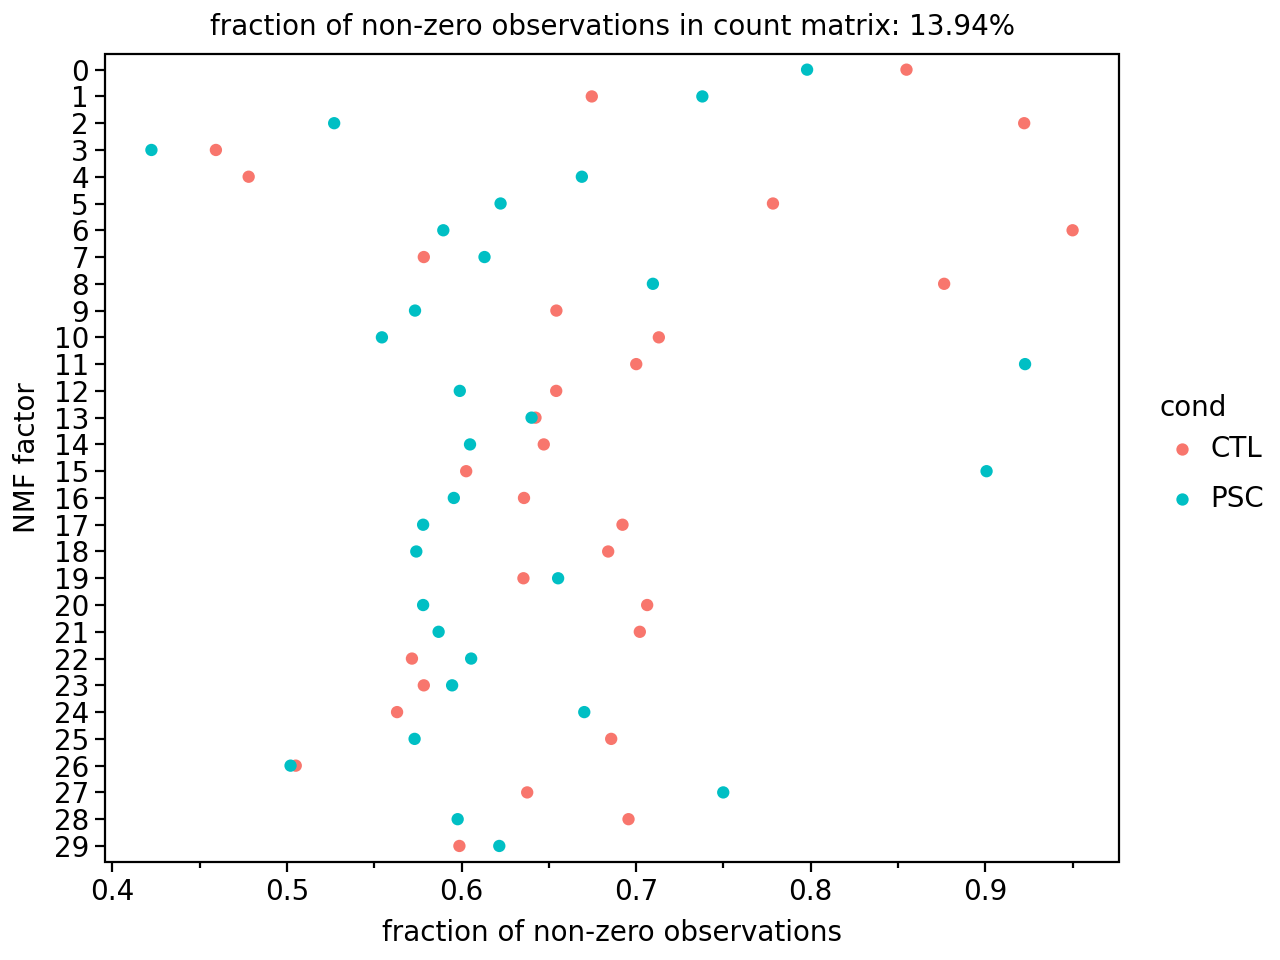

In [3]:
X_spars = psc.X.nnz / np.prod(psc.X.shape)  # ty:ignore[unresolved-attribute]
(
    comp_sparsity(psc.obsm["X_nmf"], cond=psc.obs["group"])
    >> ggplot()
    + aes(x="density", y="column", color="cond")
    + geom_point()
    + scale_y_discrete(limits=reversed)  # ty:ignore[invalid-argument-type]
    + labs(
        x="fraction of non-zero observations",
        y="NMF factor",
        title=f"fraction of non-zero observations in count matrix: {X_spars * 100:.02f}%",
    )
).show()

In [4]:
# run factor-wise regression step
for k in range(psc.obsm["X_nmf"].shape[1]):
    sP.run_fact_reg(psc, "group", "CTL", k, f"sP_p_hat_k={k:02}", X_key="X_nmf")

print(psc)

AnnData object with n_obs × n_vars = 21553 × 16465
    obs: 'in_tissue', 'percent.mt', 'cell_type', 'group', 'sample_id'
    var: 'n_cells'
    uns: 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_hat_k=18', 'sP_p_hat_k=19', 'sP_p_hat_k=20', 'sP_p_hat_k=21', 'sP_p_hat_k=22', 'sP_p_hat_k=23', 'sP_p_hat_k=24', 'sP_p_hat_k=25', 'sP_p_hat_k=26', 'sP_p_hat_k=27', 'sP_p_hat_k=28', 'sP_p_hat_k=29'
    obsm: 'spatial', 'X_nmf', 'sP_p_hat_k=00', 'sP_p_hat_k=01', 'sP_p_hat_k=02', 'sP_p_hat_k=03', 'sP_p_hat_k=04', 'sP_p_hat_k=05', 'sP_p_hat_k=06', 'sP_p_hat_k=07', 'sP_p_hat_k=08', 'sP_p_hat_k=09', 'sP_p_hat_k=10', 'sP_p_hat_k=11', 'sP_p_hat_k=12', 'sP_p_hat_k=13', 'sP_p_hat_k=14', 'sP_p_hat_k=15', 'sP_p_hat_k=16', 'sP_p_hat_k=17', 'sP_p_

we now assess our resulting regression outputs distributions \
we can extract and collate the model betas and other statistics using the sweep_uns function

/workspaces/.venv/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log


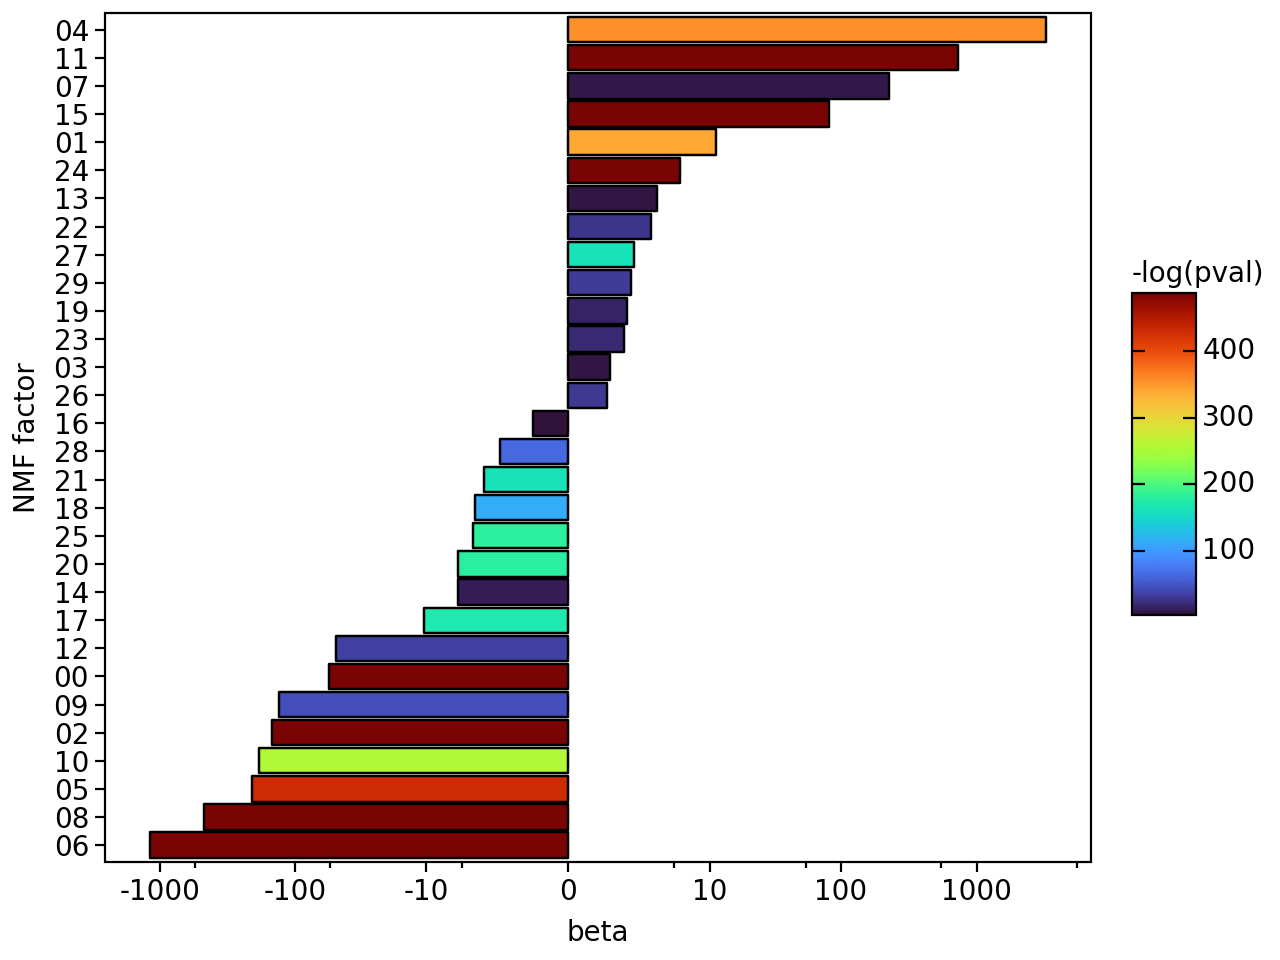

In [5]:
(
    sweep_uns(psc, "sP_p_hat_k={k}")
    >> ggplot()
    + aes(x="reorder(k, beta)", fill="-np.log(pval)", y="beta")
    + geom_col(color="black")
    + coord_flip()
    + labs(fill="-log(pval)", x="NMF factor")
    + scale_fill_cmap("turbo")
    + scale_y_symlog()
).show()

we can see that factor 4 has a strong case-specific profile \
we plot its (and associated p_hat) distributions below:

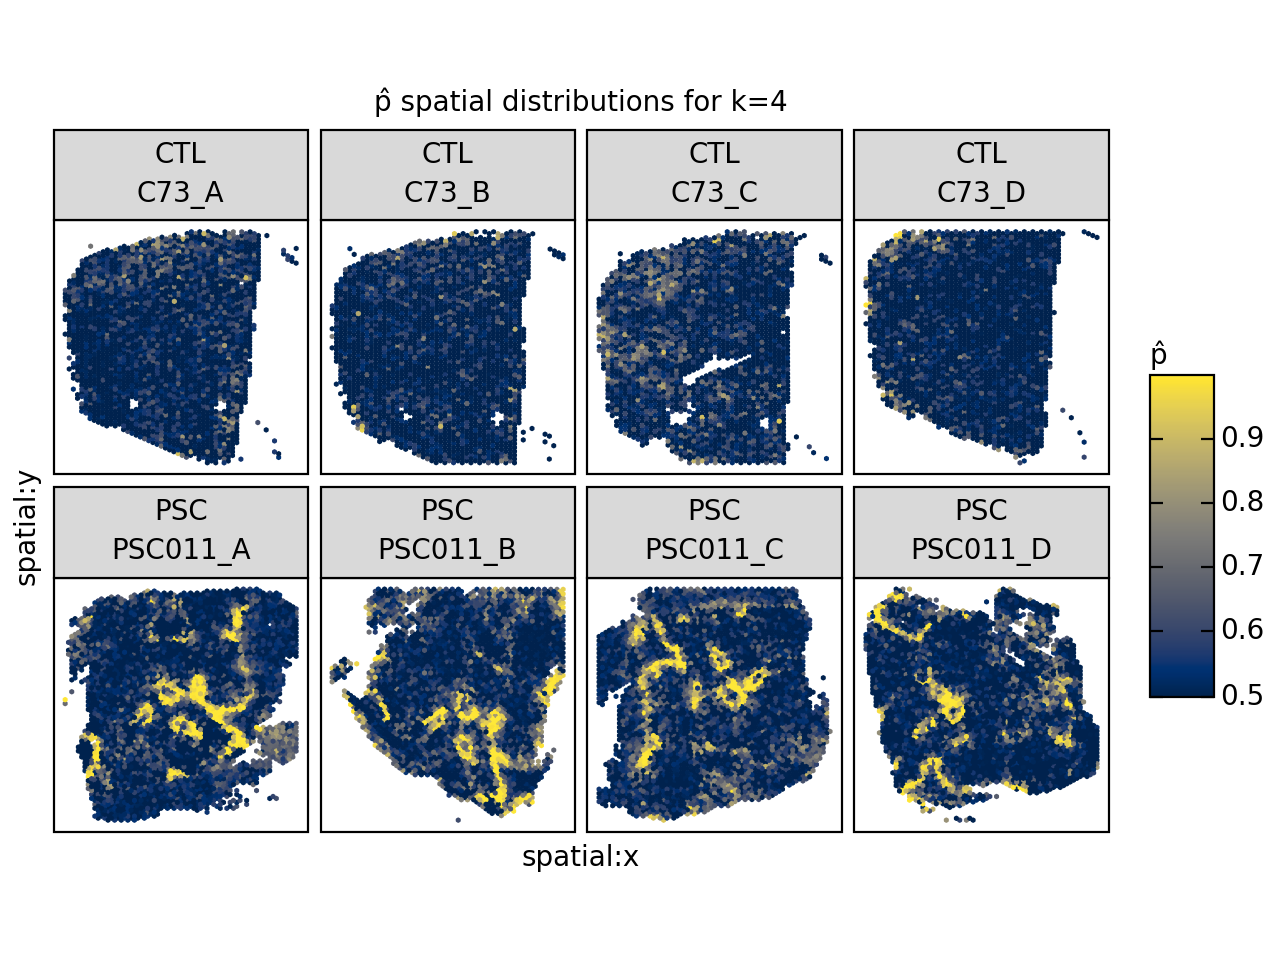

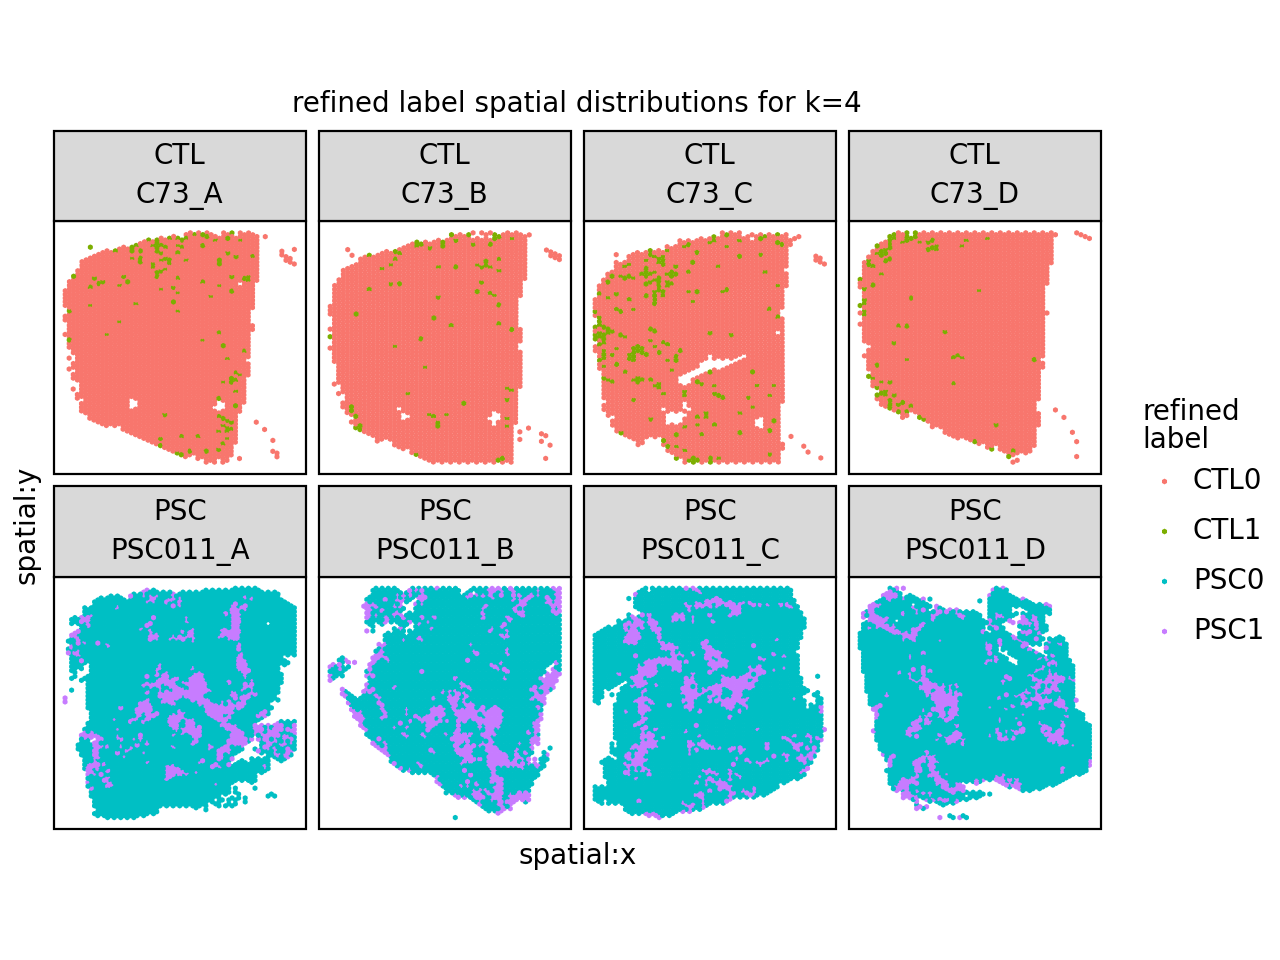

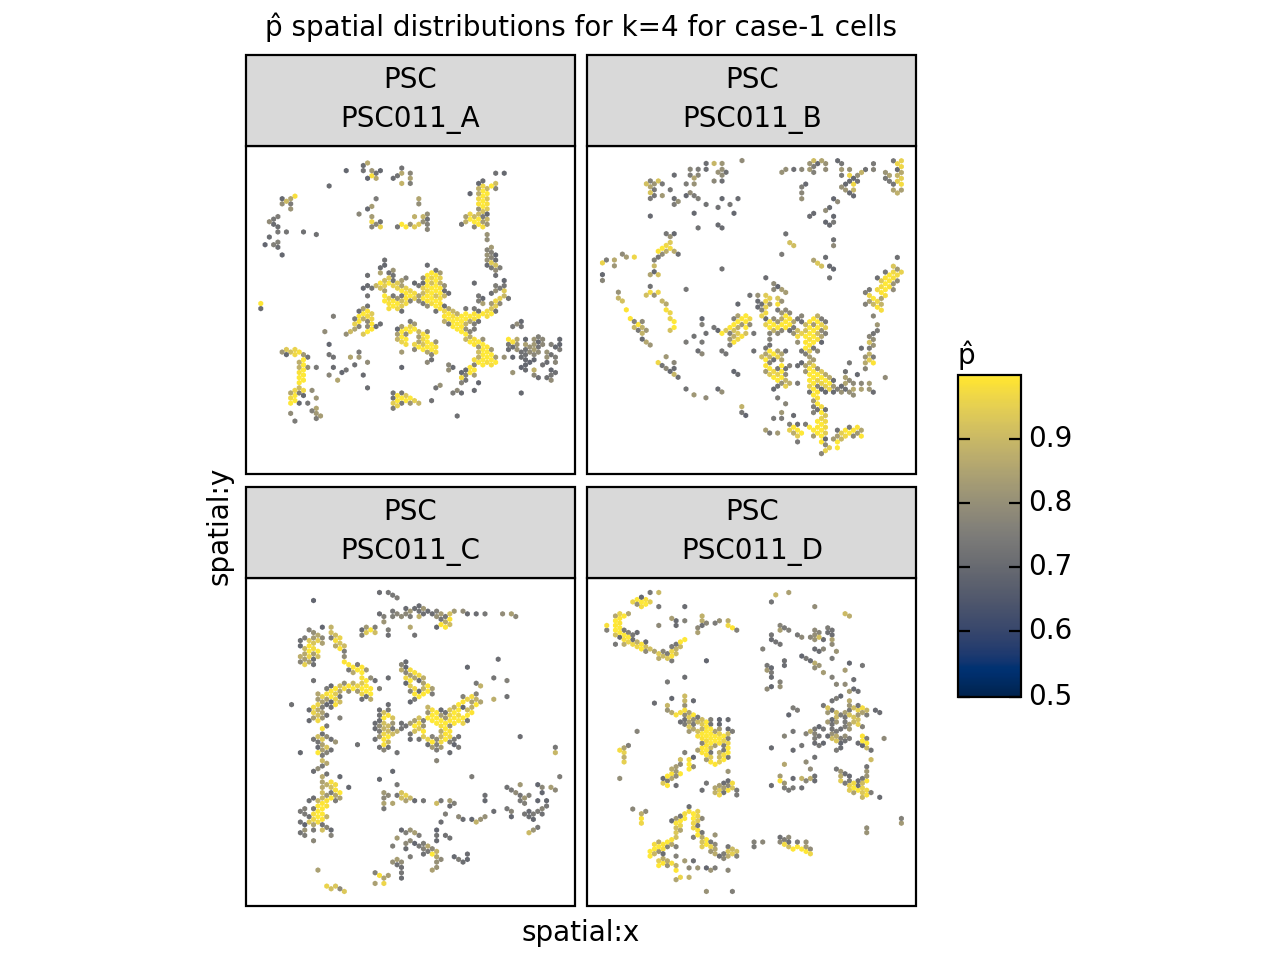

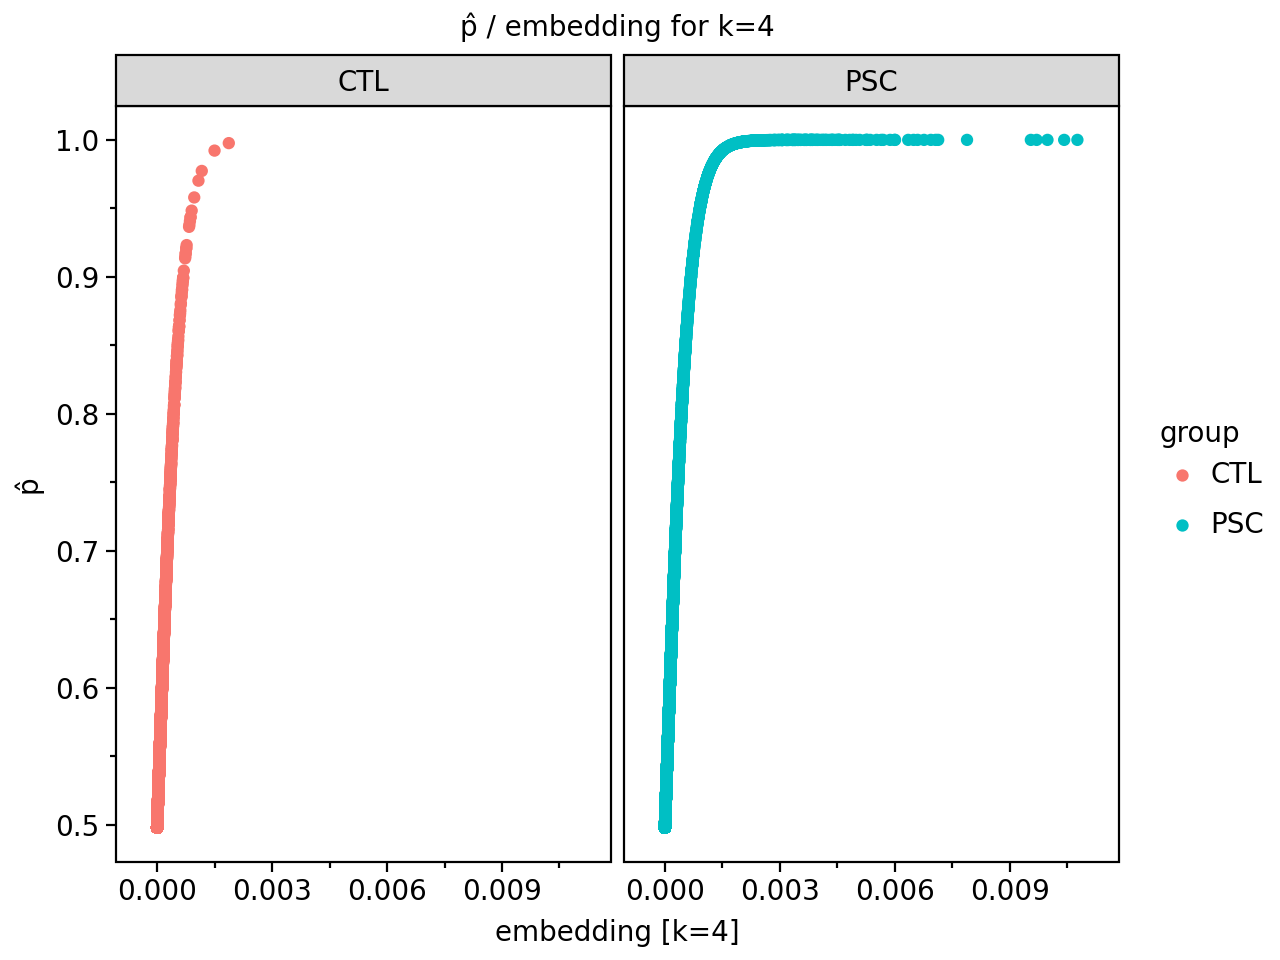

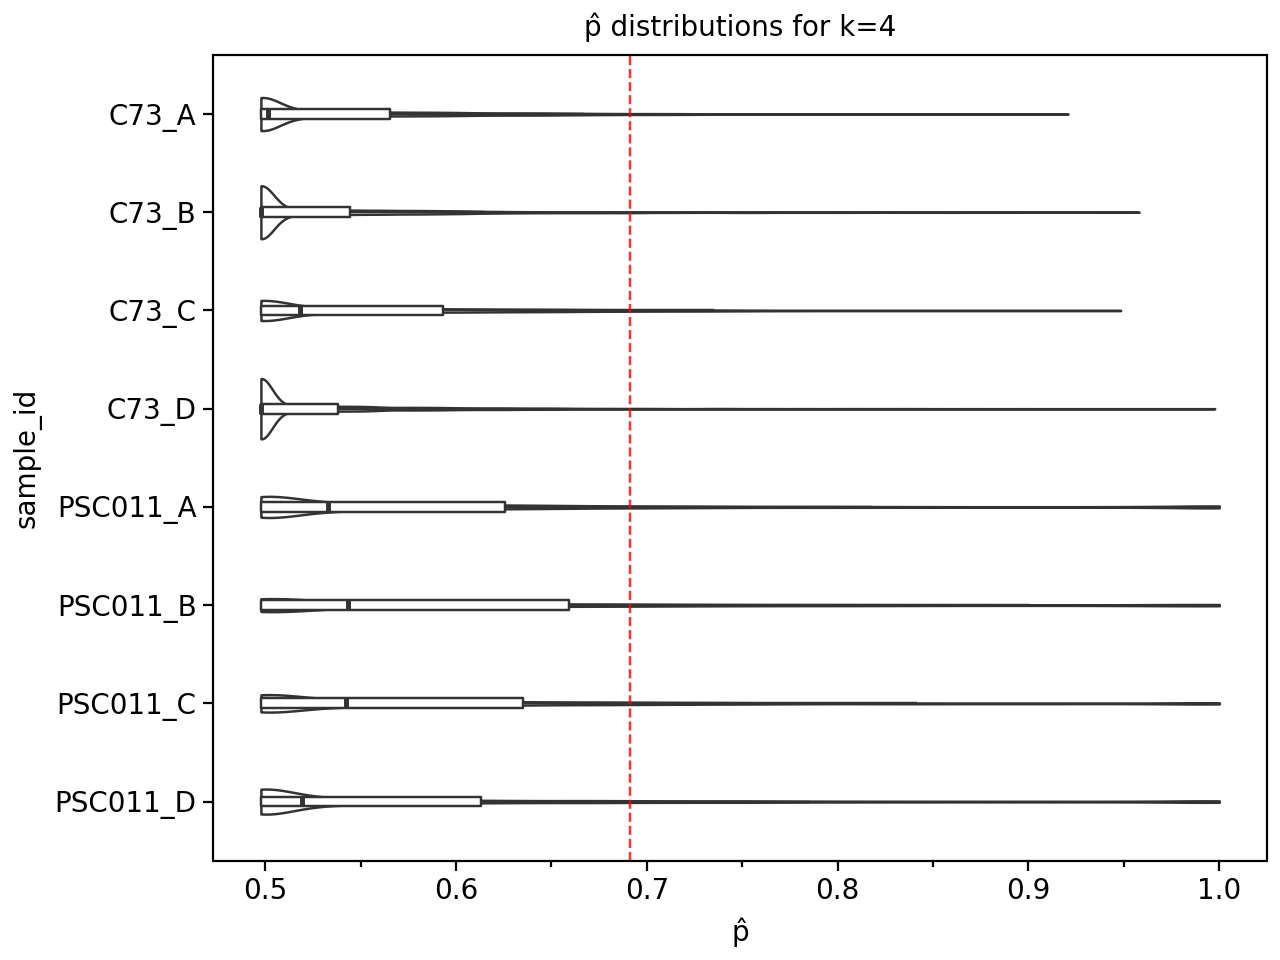

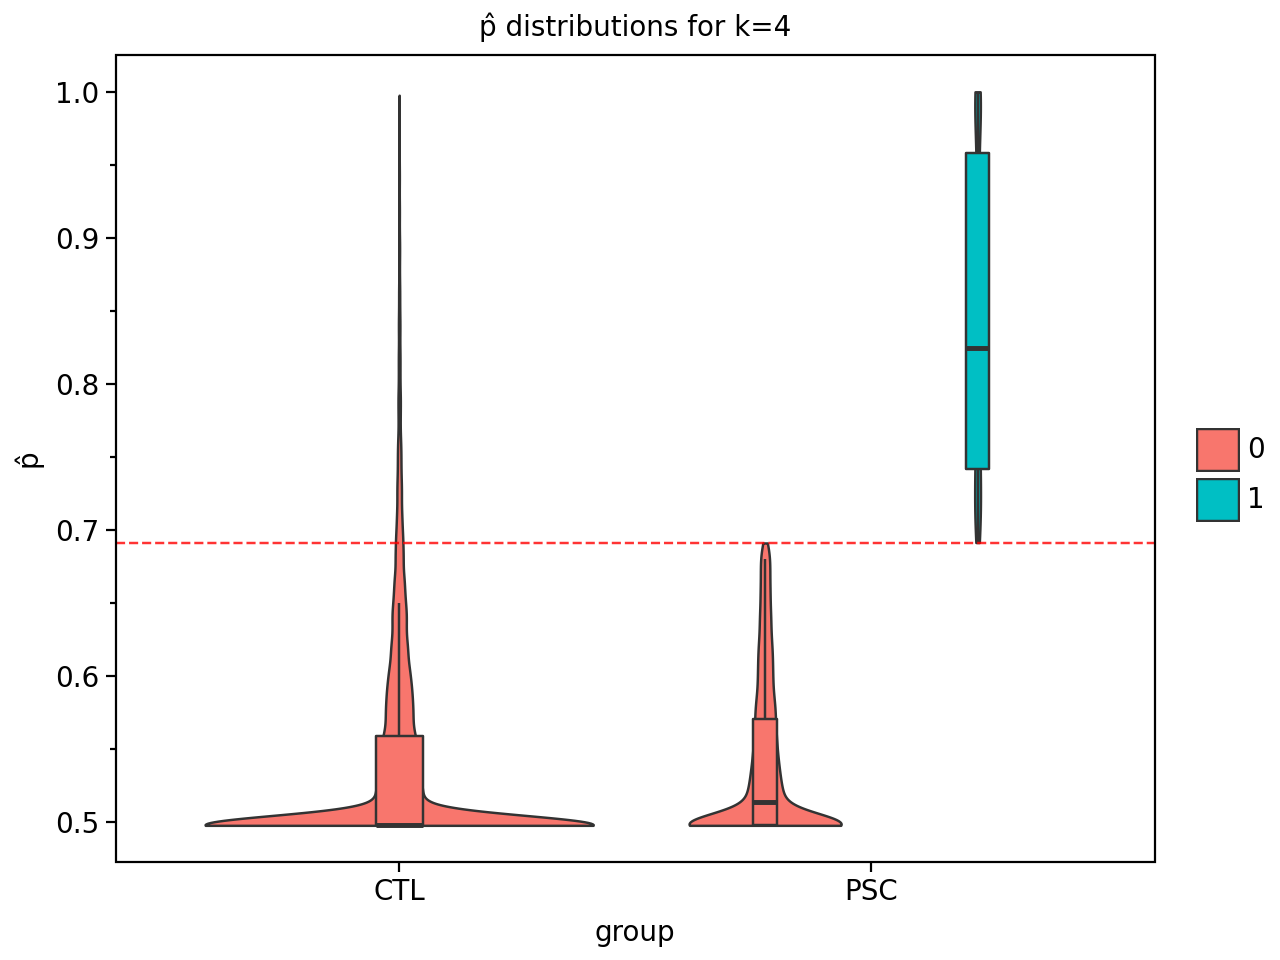

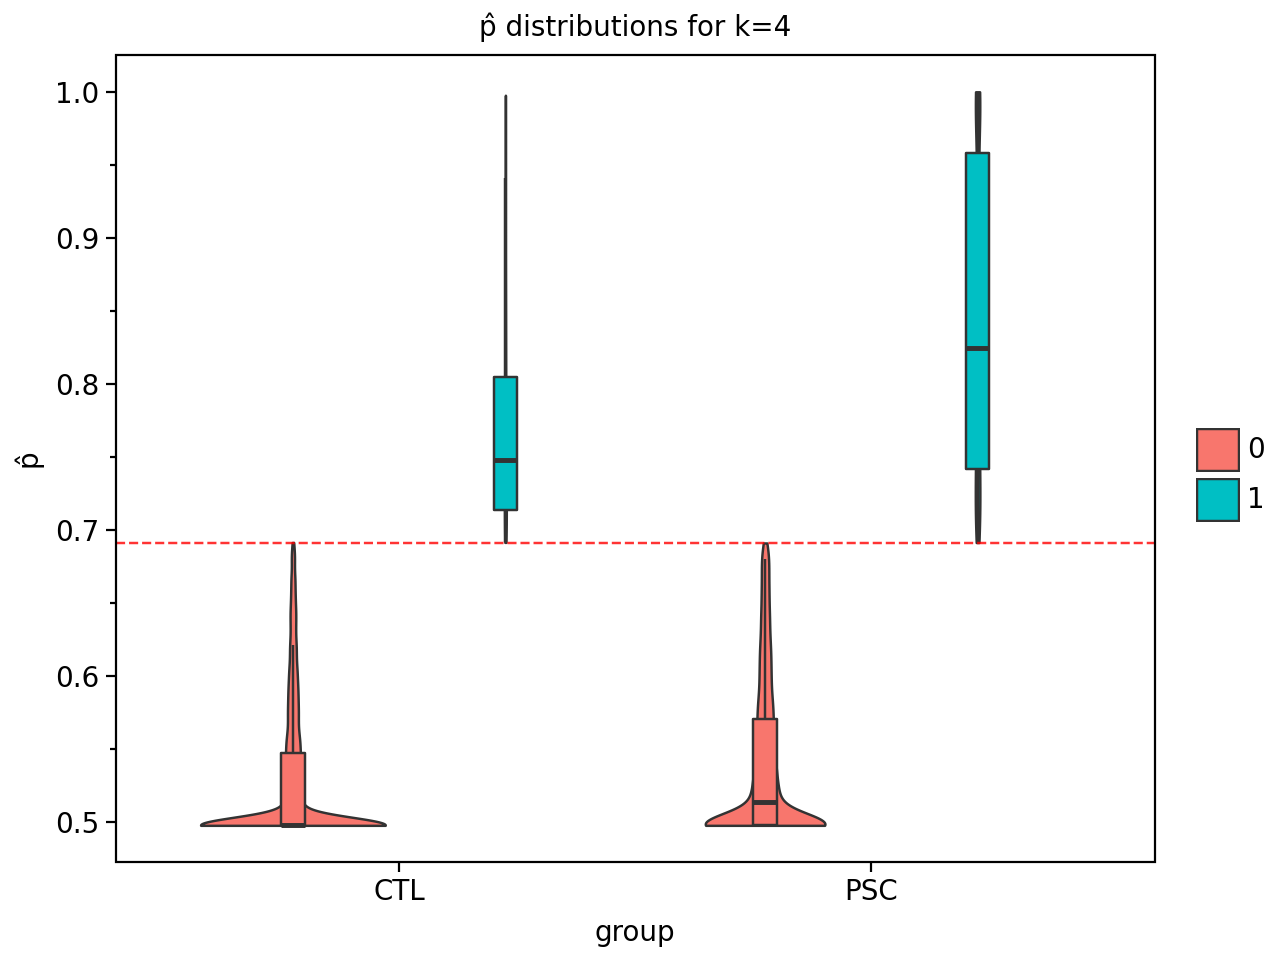

In [6]:
for k in [4]:
    for p in pl_help(psc, k).values():
        p.show()

we can also see that factor 6 shows a strong control-specific profile \
we plot its (and associated p_hat) distributions below:

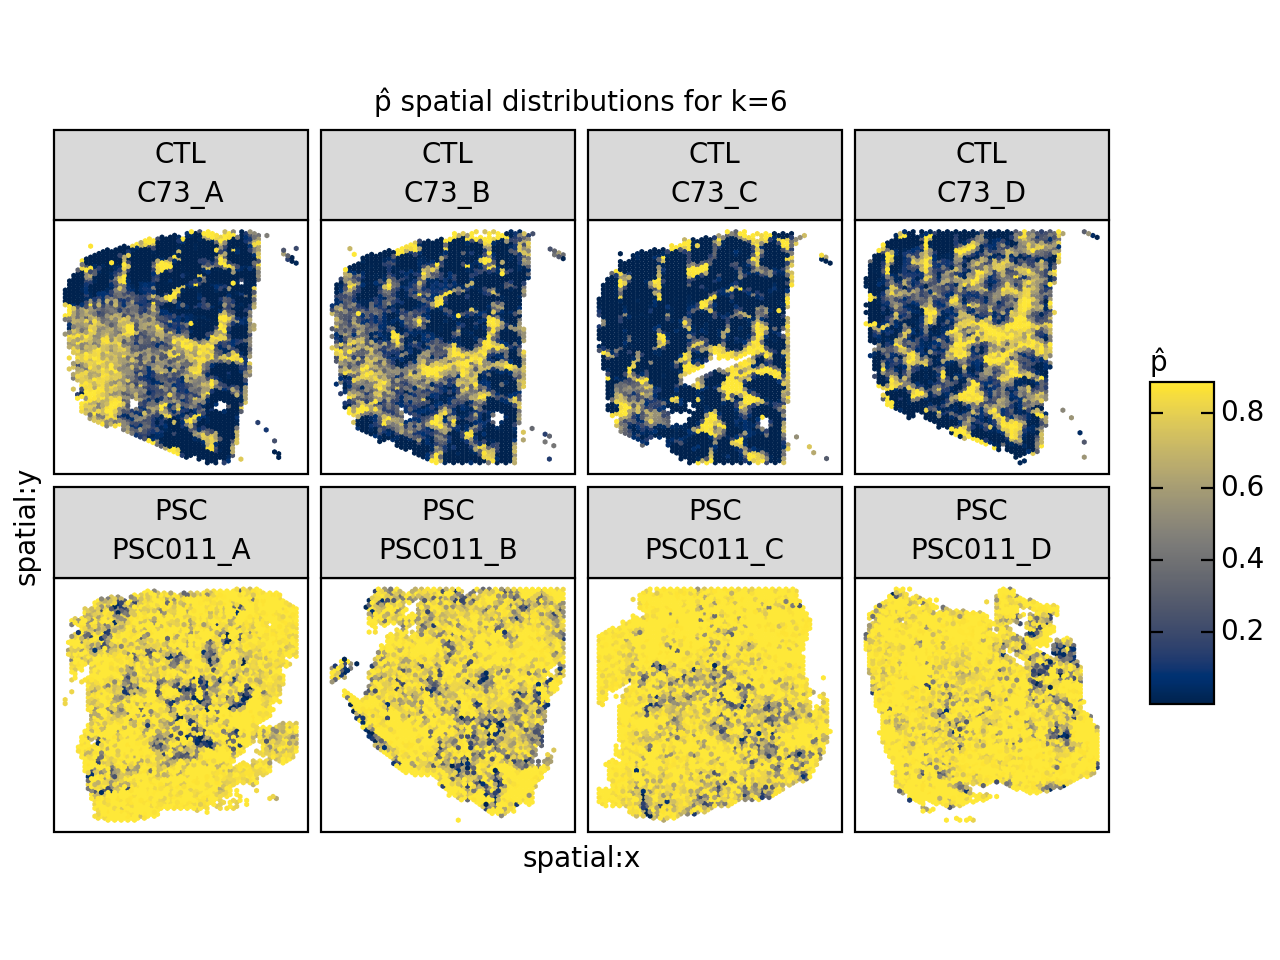

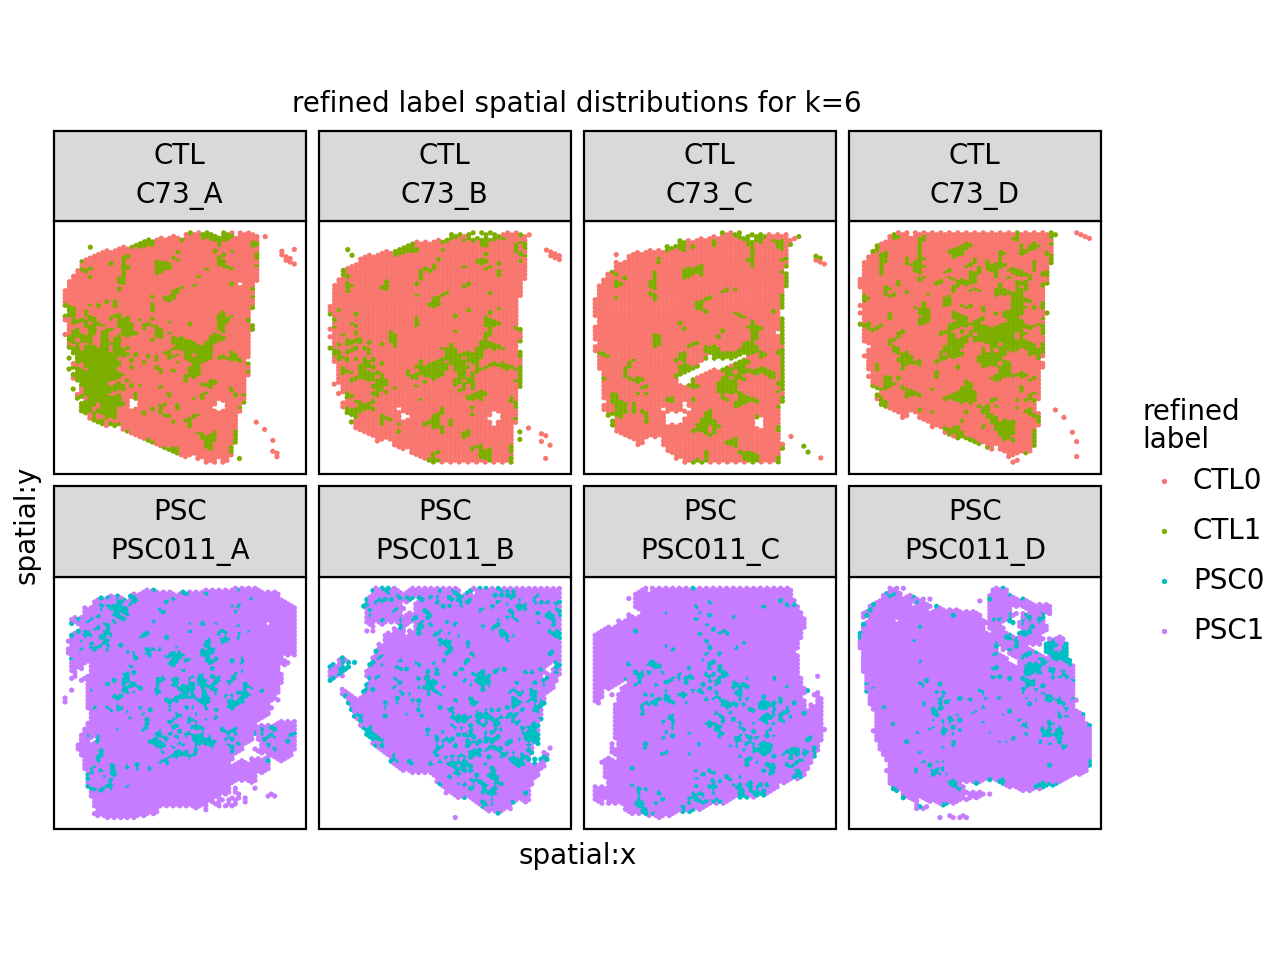

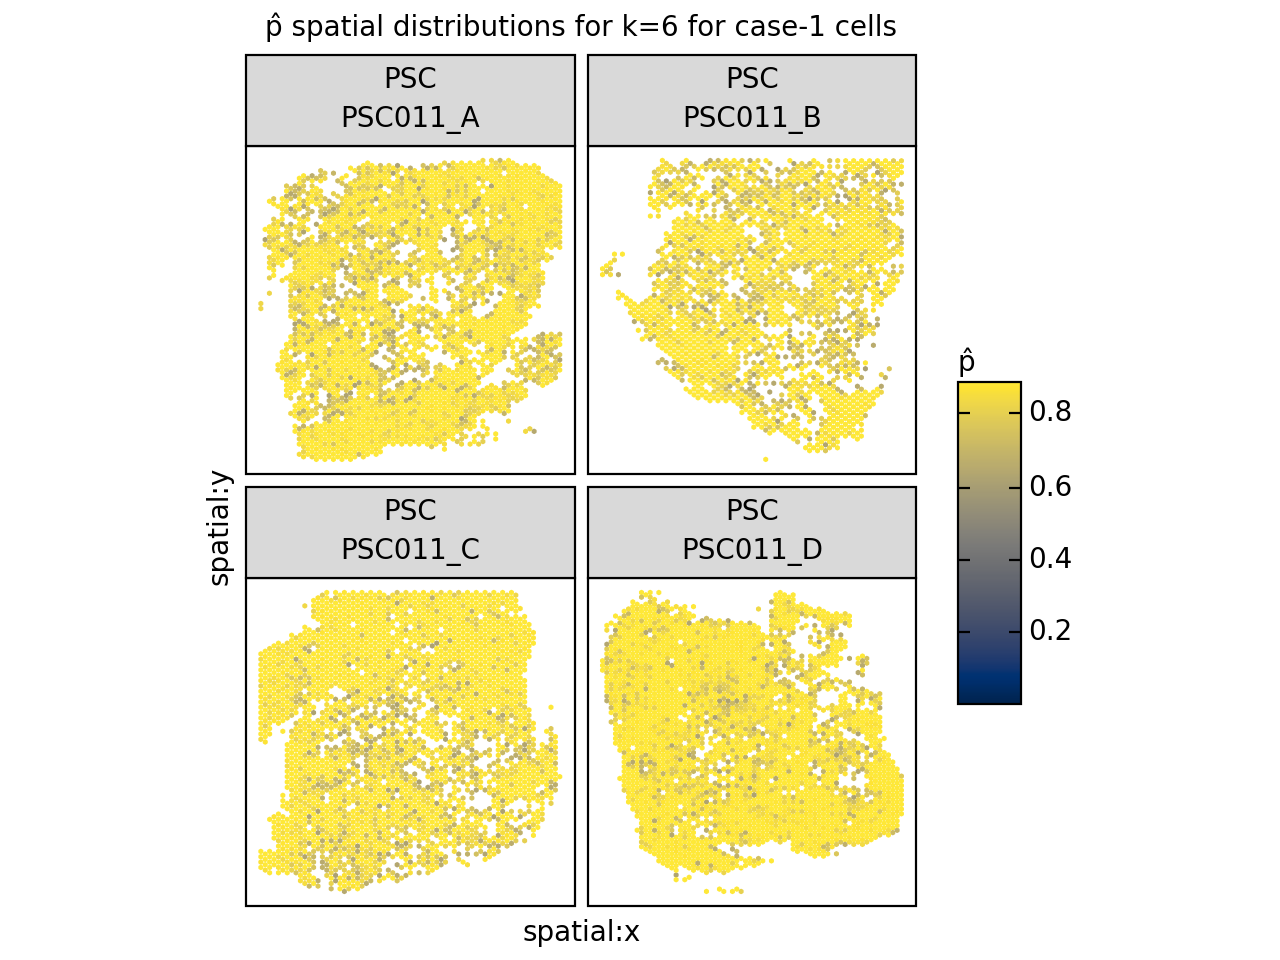

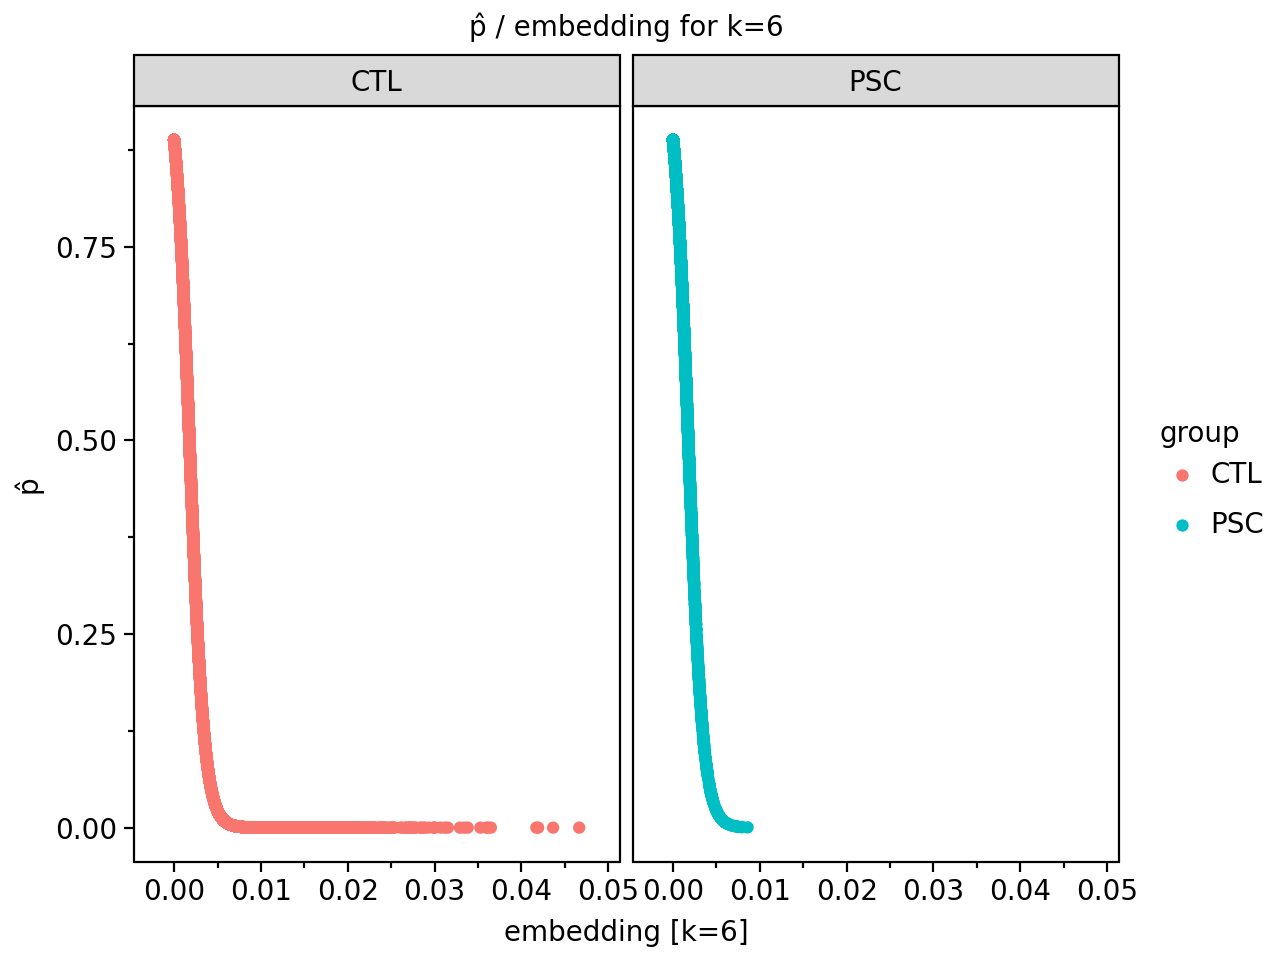

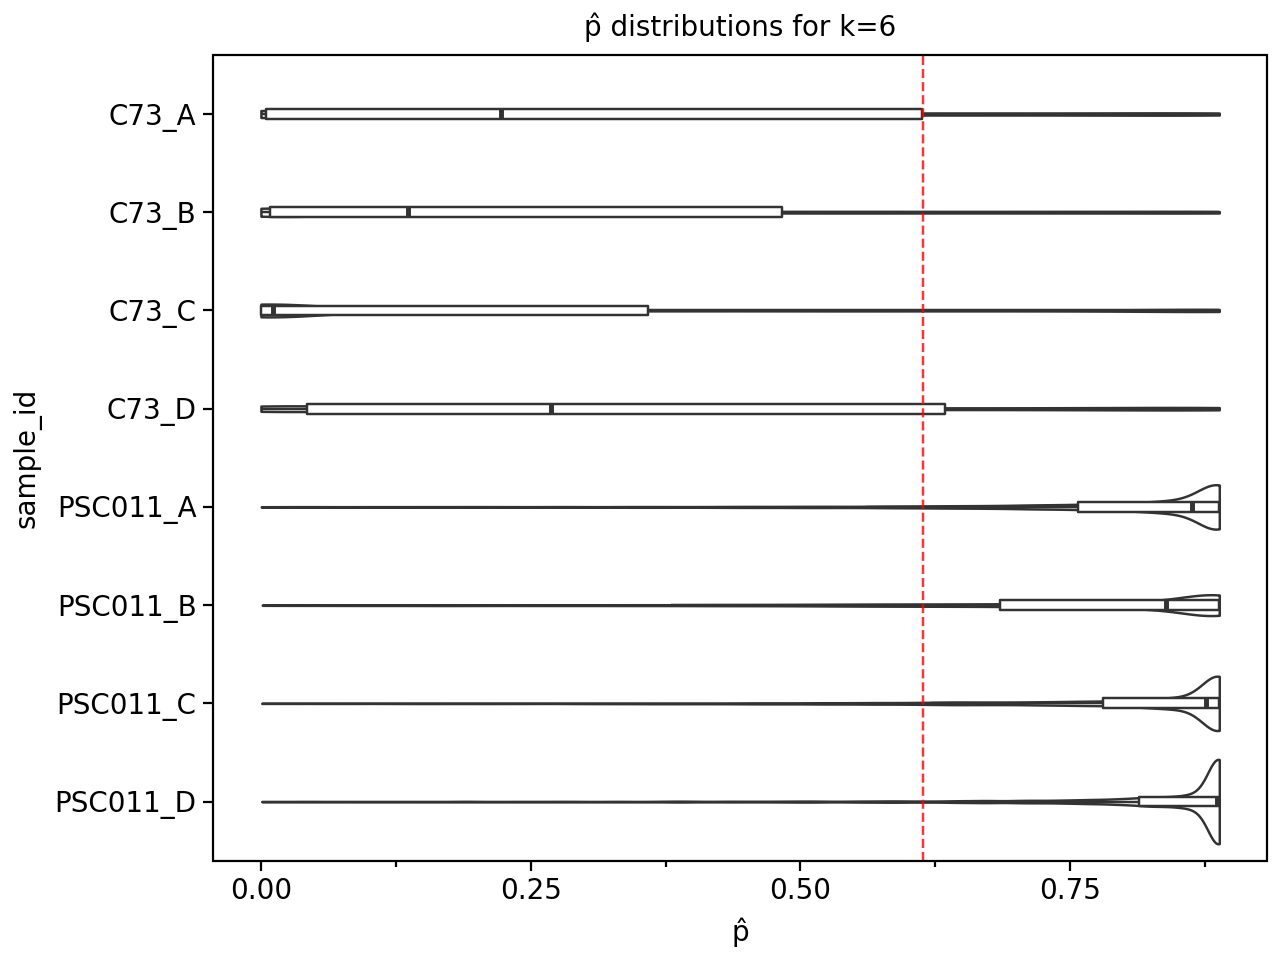

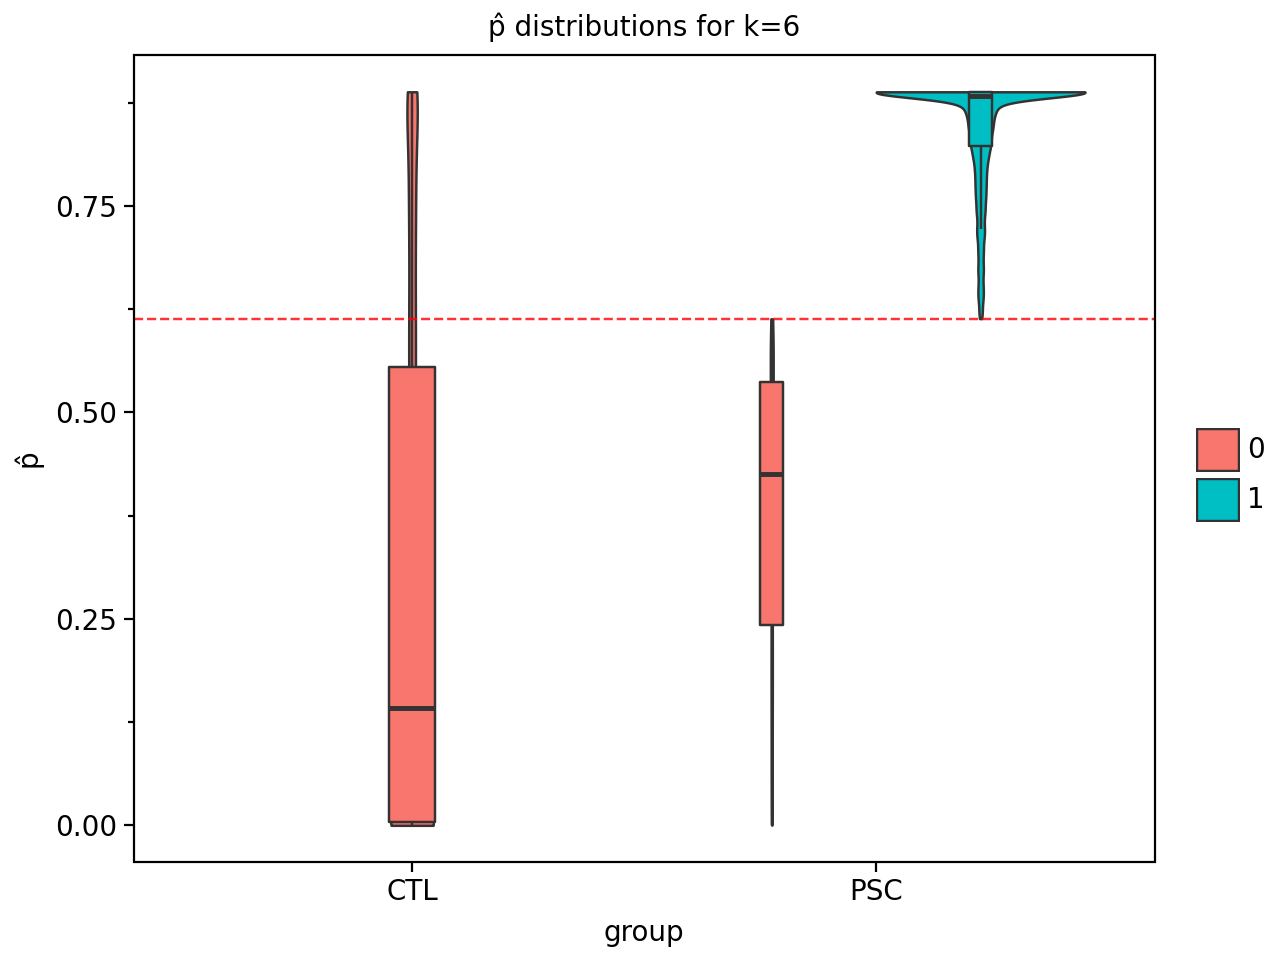

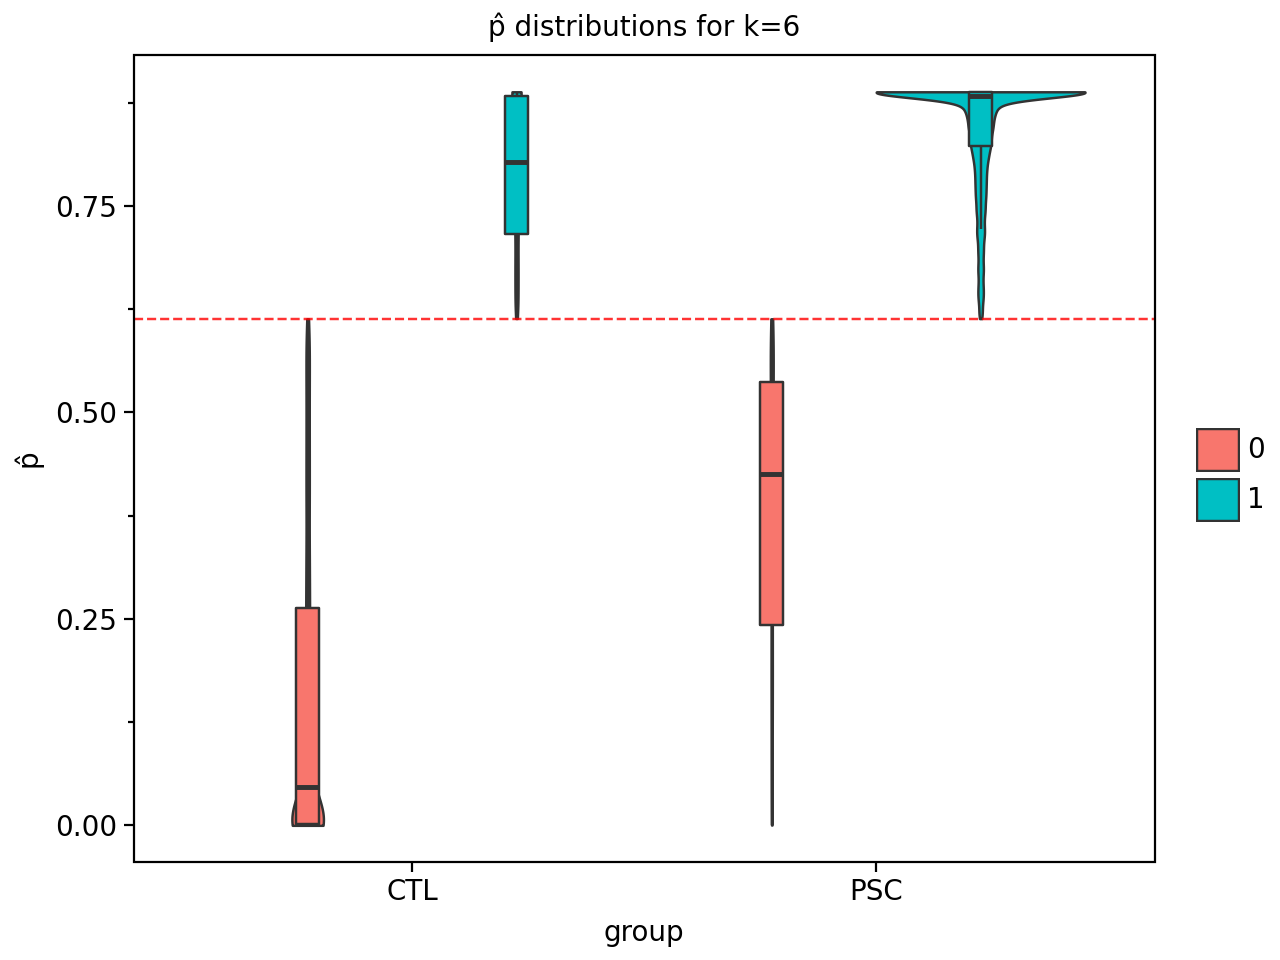

In [7]:
for k in [6]:
    for p in pl_help(psc, k).values():
        p.show()